## Confidence Intervals

### Learning Goals
* Calculate a confidence interval for a population mean using the Student's $t$-distribution critical values.
* Interpret the long-run coverage property of confidence intervals correctly.
* Understand the core assumptions and sample size behavior of confidence intervals.

---

### 1. Computing a $t$-Confidence Interval

When the population standard deviation is unknown and sample sizes are small or moderate, we use the Student's $t$-distribution to construct a confidence interval for the population mean $\mu$:
$$
\bar{x} \pm t^* \cdot \frac{s}{\sqrt{n}}
$$
where $t^*$ is the critical value from a $t$-distribution with $n-1$ degrees of freedom for a given confidence level (e.g., 95%).

In [1]:
import numpy as np
from scipy import stats

observations = np.array([12, 14, 13, 15, 11, 16, 14, 13, 12, 15])
n = len(observations)
mean = observations.mean()
se = stats.sem(observations)  # Standard error of the mean (s / sqrt(n))

# Critical value for a 95% confidence interval with n-1 degrees of freedom
critical = stats.t.ppf(0.975, df=n-1)
ci = (mean - critical * se, mean + critical * se)

print(f"Sample Mean: {mean:.2f}")
print(f"Estimated Standard Error: {se:.4f}")
print(f"95% t-Confidence Interval: ({ci[0]:.2f}, {ci[1]:.2f})")

Sample Mean: 13.50
Estimated Standard Error: 0.5000
95% t-Confidence Interval: (12.37, 14.63)


### 2. Visualizing the Interval

Visualizing an interval helps communicate estimation uncertainty clearly, anchoring the sample mean against its margin of error.

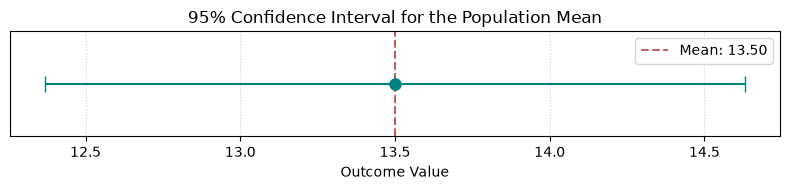

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 2))
plt.errorbar(mean, 0, xerr=[[mean - ci[0]], [ci[1] - mean]], fmt="o", color='teal', capsize=6, markersize=8)
plt.axvline(mean, color='darkred', linestyle="--", alpha=0.6, label=f"Mean: {mean:.2f}")
plt.yticks([])
plt.xlabel("Outcome Value")
plt.title("95% Confidence Interval for the Population Mean")
plt.legend(loc="upper right")
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Interpretation and Assumptions

> **Correct Interpretation:** In repeated sampling under identical conditions, 95% of the intervals built using this procedure would successfully cover the true, fixed population mean. After a specific interval is calculated, it either covers the parameter ($\mu$) or it does not; probability statements apply to the *procedure*, not a single fixed interval.

* **Assumptions:** 
  * For small samples, a $t$-interval is most reliable when observations are independent and the population is roughly bell-shaped (free of severe outliers).
  * For large samples, the procedure is robust against mild non-normality due to the Central Limit Theorem.

---

### Exercises

Try each problem before running the verification code below:

1. Explain why a wider confidence interval can sometimes be "more honest" than a narrow one.
2. What happens to the width of a confidence interval if the sample size $n$ increases while variability remains constant?
3. Interpret a 90% confidence interval correctly without stating that there is a 90% probability the fixed parameter lies inside it.

In [3]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Why a Wider Interval Can Be More Honest:")
print("   - A wider interval reflects higher uncertainty (due to small sample size or high")
print("     variance). Claiming false precision with a narrow interval can be misleading.")

print("\n2. Impact of Sample Size (n) on Width:")
print("   - As n increases, the standard error decreases (proportional to 1/sqrt(n)),")
print("     making the margin of error smaller and the confidence interval narrower.")

print("\n3. Correct Interpretation of a 90% Interval:")
print("   - 'If we were to repeat this sampling process many times, about 90% of the")
print("     resulting confidence intervals would capture the true population mean.'")

=== Exercise Solutions & Checks ===

1. Why a Wider Interval Can Be More Honest:
   - A wider interval reflects higher uncertainty (due to small sample size or high
     variance). Claiming false precision with a narrow interval can be misleading.

2. Impact of Sample Size (n) on Width:
   - As n increases, the standard error decreases (proportional to 1/sqrt(n)),
     making the margin of error smaller and the confidence interval narrower.

3. Correct Interpretation of a 90% Interval:
   - 'If we were to repeat this sampling process many times, about 90% of the
     resulting confidence intervals would capture the true population mean.'
